# Листок № 1 — СЛАУ, матрицы

**Импорты.** `numpy` — матрицы, `sympy` — символьный RREF и красивый вывод.

In [2]:
import numpy as np
import scipy.linalg as la
from sympy import *
init_printing()

---
## 1.1. Общее решение СЛАУ

$$
\begin{cases}
x_1 + 5x_2 - 2x_3 = -7, \\
-3x_1 + x_2 + 9x_3 - 5x_4 = 9, \\
4x_1 - 8x_2 - x_3 + 7x_4 = 0.
\end{cases}
$$

**Матрица коэффициентов $A$** ($3 \times 4$). Столбец $j$ — коэффициенты при $x_j$.

In [9]:
A=np.array([[1,5,-2,0],[-3,1,9,-5],[4,-8,-1,7]])

**Столбец правых частей $b$.**

In [10]:
b=np.array([-7,9,0]).reshape(3,1)

**Расширенная матрица** $(A \mid b)$.

In [11]:
A_b=np.hstack([A,b])

**RREF.** Базисные: $x_1, x_2, x_3$; свободная: $x_4$.

$$x_1 = -\tfrac{11}{7} - \tfrac{8}{7}x_4,\quad x_2 = -\tfrac{6}{7} + \tfrac{2}{7}x_4,\quad x_3 = \tfrac{4}{7} + \tfrac{1}{7}x_4,\quad x_4 \in \mathbb{R}.$$

In [12]:
Matrix(A_b).rref()

⎛⎡1  0  0  8/7   -11/7⎤           ⎞
⎜⎢                    ⎥           ⎟
⎜⎢0  1  0  -2/7  -6/7 ⎥, (0, 1, 2)⎟
⎜⎢                    ⎥           ⎟
⎝⎣0  0  1  -1/7   4/7 ⎦           ⎠

---
## 1.2. RREF и общее решение СЛАУ

$$
\begin{cases}
5x_1 - x_2 + 5x_3 + 9x_4 - 2x_5 = -3, \\
3x_1 + 6x_3 + 9x_4 - x_5 = 4, \\
2x_1 + 4x_3 + 6x_4 - x_5 = 0.
\end{cases}
$$

Найти: **а)** RREF; **б)** общее решение.

**Матрица $A$** ($3 \times 5$). Во 2-м и 3-м уравнениях нет $x_2$ → коэффициент $0$.

In [13]:
A=np.array([[5,-1,5,9,-2],[3,0,6,9,-1],[2,0,4,6,-1]])
print(A)

[[ 5 -1  5  9 -2]
 [ 3  0  6  9 -1]
 [ 2  0  4  6 -1]]


**Столбец $b$.**

In [14]:
b=np.array([-3,4,0]).reshape(3,1)
print(b)

[[-3]
 [ 4]
 [ 0]]


**Расширенная матрица** $(A \mid b)$.

In [15]:
A_b=np.hstack([A,b])
print(A_b)

[[ 5 -1  5  9 -2 -3]
 [ 3  0  6  9 -1  4]
 [ 2  0  4  6 -1  0]]


**а) RREF.** Базисные: $x_1, x_2, x_5$; свободные: $x_3, x_4$.

**б) Общее решение:**
$$x_1 = 4 - 2x_3 - 3x_4,\quad x_2 = 7 - 5x_3 - 6x_4,\quad x_3, x_4 \in \mathbb{R},\quad x_5 = 8.$$

In [16]:
Matrix(A_b).rref()

⎛⎡1  0  2  3  0  4⎤           ⎞
⎜⎢                ⎥           ⎟
⎜⎢0  1  5  6  0  7⎥, (0, 1, 4)⎟
⎜⎢                ⎥           ⎟
⎝⎣0  0  0  0  1  8⎦           ⎠

---
## 1.3. Зависимость $y$ от $x$

$$
\begin{cases}
32x + 97y + 90z + 48u = 47, \\
35x + 84y + 91z + 54u = 40, \\
17x + 18y + 21z + 13u = 37.
\end{cases}
$$

**Почему $y = a + bx$?** 4 неизвестных, 3 уравнения → одна свободная переменная. Все решения — прямая в $\mathbb{R}^4$, поэтому $x$, $y$, $z$, $u$ **линейно** зависят от параметра. Исключив параметр, получаем линейную связь $y = a + bx$.

**Матрица $A$** ($3 \times 4$). Столбцы — коэффициенты при $x, y, z, u$.

In [17]:
A=np.array([[32,97,90,48],[35,84,91,54],[17,18,21,13]])

**Столбец $b$.**

In [18]:
b=np.array([47,40,37]).reshape(3,1)

**Расширенная матрица** $(A \mid b)$ и **RREF**. Базисные: $x, y, z$; свободная: $u$.

In [19]:
A_b=np.hstack([A,b])
Matrix(A_b).rref()

⎛⎡                   36121 ⎤           ⎞
⎜⎢1  0  0  1/10976   ───── ⎥           ⎟
⎜⎢                   10976 ⎥           ⎟
⎜⎢                         ⎥           ⎟
⎜⎢         -2131     6325  ⎥           ⎟
⎜⎢0  1  0  ──────    ────  ⎥, (0, 1, 2)⎟
⎜⎢          5488     5488  ⎥           ⎟
⎜⎢                         ⎥           ⎟
⎜⎢          10447   -20745 ⎥           ⎟
⎜⎢0  0  1   ─────   ───────⎥           ⎟
⎝⎣          10976    10976 ⎦           ⎠

**Из RREF** (свободная $u$):
$$x = \tfrac{36121}{10976} - \tfrac{u}{10976}, \quad y = \tfrac{6325}{5488} + \tfrac{2131}{5488}\, u.$$

Подставляем $u = 36121 - 10976\,x$ → получаем $y = a + bx$:

In [20]:
u = symbols('u')
x, y = symbols('x y')

x_u = Rational(36121, 10976) - u/10976
y_u = Rational(6325, 5488) + Rational(2131, 5488)*u

y_x = expand(y_u.subs(u, 36121 - 10976*x))
Eq(y, y_x)

**Ответ:** $y = 14027 - 4262\,x$, то есть **$a = 14027$**, **$b = -4262$**.

---
## 1.4. Действия с матрицами

$$
\begin{pmatrix}
3 & 0 & 2 \\
0 & 1 & 3 \\
2 & 2 & 0 \\
0 & 1 & 0
\end{pmatrix}
\cdot
\begin{pmatrix}
1 & 2 & -1 & 2 \\
-2 & -1 & 1 & 2 \\
2 & 1 & 1 & 2
\end{pmatrix}
+
\begin{pmatrix}
0 & -4 & 6 & 1 \\
2 & 2 & -5 & -2 \\
2 & -2 & 6 & 4 \\
1 & 3 & 0 & 1
\end{pmatrix}.
$$

Сначала умножение, потом сложение. Размеры согласованы: $(4\times 3)\cdot(3\times 4) = 4\times 4$, плюс матрица $4\times 4$.

**Матрица $A$** ($4 \times 3$), левый множитель.

In [21]:
A=np.array([[3,0,2],[0,1,3],[2,2,0],[0,1,0]])
print(A)

[[3 0 2]
 [0 1 3]
 [2 2 0]
 [0 1 0]]


**Матрица $B$** ($3 \times 4$), правый множитель. Число столбцов $A$ = число строк $B$ $= 3$, умножение возможно.

In [22]:
B=np.array([[1,2,-1,2],[-2,-1,1,2],[2,1,1,2]])
print(B)

[[ 1  2 -1  2]
 [-2 -1  1  2]
 [ 2  1  1  2]]


**Матрица $C$** ($4 \times 4$). Её прибавим к произведению $AB$.

In [23]:
C=np.array([[0,-4,6,1],[2,2,-5,-2],[2,-2,6,4],[1,3,0,1]])
print(C)

[[ 0 -4  6  1]
 [ 2  2 -5 -2]
 [ 2 -2  6  4]
 [ 1  3  0  1]]


**Произведение $AB$.** Элемент $(i,j)$ — скалярное произведение $i$-й строки $A$ на $j$-й столбец $B$. Результат $4\times 4$.

In [24]:
AB=A@B
Matrix(AB)

⎡7   8   -1  10⎤
⎢              ⎥
⎢4   2   4   8 ⎥
⎢              ⎥
⎢-2  2   0   8 ⎥
⎢              ⎥
⎣-2  -1  1   2 ⎦

**Сумма $AB+C$.** Складываем поэлементно матрицы одного размера.

In [25]:
Matrix(AB+C)

⎡7   4  5   11⎤
⎢             ⎥
⎢6   4  -1  6 ⎥
⎢             ⎥
⎢0   0  6   12⎥
⎢             ⎥
⎣-1  2  1   3 ⎦

**Ответ:**
$$
AB+C =
\begin{pmatrix}
7 & 4 & 5 & 11 \\
6 & 4 & -1 & 6 \\
0 & 0 & 6 & 12 \\
-1 & 2 & 1 & 3
\end{pmatrix}.
$$

---
## 1.5. Определители порядка $n$

Найти $\det A$, если $A$ размера $n\times n$ и
**а)** $a_{ij}=\min(i,j)$;
**б)** $a_{ij}=\max(i,j)$;
**в)** $a_{ij}=|i-j|$.

Индексы $i,j$ от $1$ до $n$. Сначала считаем $\det$ при $n=1,2,\ldots$ и угадываем формулу, потом доказываем её элементарными преобразованиями (определитель не меняется).

**Сборка матрицы.** `i+1, j+1`, потому что в Python индексы с нуля, а в задаче — с единицы.

In [26]:
def M(n, f):
    return Matrix(n, n, lambda i, j: f(i+1, j+1))

def show_dets(f, N=7):
    return [M(n, f).det() for n in range(1, N+1)]

**а)** $a_{ij}=\min(i,j)$. Пример при $n=5$ и ряд определителей.

In [27]:
M(5, min), show_dets(min)

⎛⎡1  1  1  1  1⎤                       ⎞
⎜⎢             ⎥                       ⎟
⎜⎢1  2  2  2  2⎥                       ⎟
⎜⎢             ⎥                       ⎟
⎜⎢1  2  3  3  3⎥, [1, 1, 1, 1, 1, 1, 1]⎟
⎜⎢             ⎥                       ⎟
⎜⎢1  2  3  4  4⎥                       ⎟
⎜⎢             ⎥                       ⎟
⎝⎣1  2  3  4  5⎦                       ⎠

Все определители равны $1$. Доказательство: из каждой строки вычитаем предыдущую, **снизу вверх** ($R_i\leftarrow R_i-R_{i-1}$). Тогда
$\min(i,j)-\min(i-1,j)$ равно $0$ при $j<i$ и $1$ при $j\ge i$. Получается верхняя треугольная матрица из единиц, её определитель $1$.

In [28]:
A=M(5, min)
for i in range(4, 0, -1):
    A[i,:]=A[i,:]-A[i-1,:]
A

⎡1  1  1  1  1⎤
⎢             ⎥
⎢0  1  1  1  1⎥
⎢             ⎥
⎢0  0  1  1  1⎥
⎢             ⎥
⎢0  0  0  1  1⎥
⎢             ⎥
⎣0  0  0  0  1⎦

**Ответ а):** $\det=1$ при любом $n$.

---
**б)** $a_{ij}=\max(i,j)$. Ряд: $1,-2,3,-4,5,-6,7,\ldots$ — это $(-1)^{n-1}n$.

In [29]:
M(5, max), show_dets(max)

⎛⎡1  2  3  4  5⎤                          ⎞
⎜⎢             ⎥                          ⎟
⎜⎢2  2  3  4  5⎥                          ⎟
⎜⎢             ⎥                          ⎟
⎜⎢3  3  3  4  5⎥, [1, -2, 3, -4, 5, -6, 7]⎟
⎜⎢             ⎥                          ⎟
⎜⎢4  4  4  4  5⎥                          ⎟
⎜⎢             ⎥                          ⎟
⎝⎣5  5  5  5  5⎦                          ⎠

Доказательство: $C_j\leftarrow C_j-C_{j+1}$ для $j=1,\ldots,n-1$ (слева направо, следующий столбец ещё не тронут). Тогда $\max(i,j)-\max(i,j+1)$ равно $-1$ при $i\le j$ и $0$ при $i\ge j+1$. Последний столбец не меняется: в нём все $n$. Получается верхняя треугольная матрица с диагональю $-1,-1,\ldots,-1,n$.

In [30]:
A=M(5, max)
for j in range(4):
    A[:,j]=A[:,j]-A[:,j+1]
A

⎡-1  -1  -1  -1  5⎤
⎢                 ⎥
⎢0   -1  -1  -1  5⎥
⎢                 ⎥
⎢0   0   -1  -1  5⎥
⎢                 ⎥
⎢0   0   0   -1  5⎥
⎢                 ⎥
⎣0   0   0   0   5⎦

**Ответ б):** $\det=(-1)^{n-1}n$.

---
**в)** $a_{ij}=|i-j|$. Ряд: $0,-1,4,-12,32,-80,192,\ldots$. При $n\ge 2$ это $(-1)^{n-1}(n-1)2^{n-2}$.

In [31]:
M(5, lambda i, j: abs(i-j)), show_dets(lambda i, j: abs(i-j))

⎛⎡0  1  2  3  4⎤                               ⎞
⎜⎢             ⎥                               ⎟
⎜⎢1  0  1  2  3⎥                               ⎟
⎜⎢             ⎥                               ⎟
⎜⎢2  1  0  1  2⎥, [0, -1, 4, -12, 32, -80, 192]⎟
⎜⎢             ⎥                               ⎟
⎜⎢3  2  1  0  1⎥                               ⎟
⎜⎢             ⎥                               ⎟
⎝⎣4  3  2  1  0⎦                               ⎠

Сначала те же разности строк снизу вверх, затем разности столбцов справа налево. Получается «окаймлённая» матрица: в углу $0$, первая строка и столбец из единиц, дальше $-2$ на диагонали. Дальше $C_1\leftarrow 2C_1+C_2+\cdots+C_n$: в первом столбце остаётся только $n-1$ в углу, остальное нули. Определитель умножился на $2$, поэтому
$$
2\det = (n-1)\cdot(-2)^{n-1} \implies \det=(-1)^{n-1}(n-1)2^{n-2}.
$$
При $n=1$ матрица $(0)$, $\det=0$.

In [32]:
A=M(5, lambda i, j: abs(i-j))
for i in range(4, 0, -1):
    A[i,:]=A[i,:]-A[i-1,:]
for j in range(4, 0, -1):
    A[:,j]=A[:,j]-A[:,j-1]
A

⎡0  1   1   1   1 ⎤
⎢                 ⎥
⎢1  -2  0   0   0 ⎥
⎢                 ⎥
⎢1  0   -2  0   0 ⎥
⎢                 ⎥
⎢1  0   0   -2  0 ⎥
⎢                 ⎥
⎣1  0   0   0   -2⎦

**Ответ в):** $\det=0$ при $n=1$; при $n\ge 2$ — $\det=(-1)^{n-1}(n-1)2^{n-2}$.

**Итого:**
- а) $1$;
- б) $(-1)^{n-1}n$;
- в) $(-1)^{n-1}(n-1)2^{n-2}$ ($n\ge 2$).

---
## 1.6. Наибольший определитель $6\times 6$ из $-1,0,1$

Найти $\max|\det A|$ среди всех матриц $6\times 6$ с элементами из $\{-1,0,1\}$.

Полный перебор $3^{36}\approx 1{,}5\cdot 10^{17}$ нереален. План: оценка сверху (Адамар), сведение к $\pm 1$, симметрии, затем перебор $\binom{31}{5}\approx 1{,}7\cdot 10^5$ матриц.

**Оценка Адамара.** $|\det A|$ — объём параллелепипеда из строк. Длина строки $\le\sqrt{6}$, равенство только без нулей. Значит $|\det A|\le(\sqrt{6})^6=216$.

Если в строке есть $0$, длина $\le\sqrt{5}$ и оценка $\approx 197$, всё ещё больше $160$. Нули скорее мешают; максимум достигается на $\pm 1$ (для $n=3$ это проверяем перебором ниже). Дальше ищем среди матриц из $\pm 1$.

**Проба на $n=3$.** Все $3^9=19683$ матрицы из $\{-1,0,1\}$: максимум $4$, как у $\pm 1$ (например $\begin{pmatrix}1&1&1\\1&1&-1\\1&-1&1\end{pmatrix}$).

In [33]:
from itertools import product, combinations

best=0
for entries in product((-1,0,1), repeat=9):
    d=abs(Matrix(3,3,entries).det())
    if d>best:
        best=d
best

**Симметрии для $\pm 1$ матриц $6\times 6$.** Умножение строки или столбца на $-1$ меняет только знак $\det$, не $|\det|$. Поэтому можно считать:
- первая строка вся из $+1$ (домножили столбцы);
- первый столбец тоже из $+1$ (домножили остальные строки).

Тогда остальные $5$ строк — это векторы из $\pm 1$ длины $6$, начинающиеся с $+1$, кроме $(1,1,1,1,1,1)$. Таких $31$. Переставлять выбранные $5$ строк незачем: перестановка меняет только знак. Остаётся $\binom{31}{5}=169911$ наборов.

In [34]:
rows=[]
for mask in range(1, 32):
    r=np.ones(6, dtype=int)
    for k in range(5):
        if mask & (1<<k):
            r[k+1]=-1
    rows.append(r)
rows=np.array(rows)

first=np.ones(6, dtype=int)
best=0
bestA=None
for comb in combinations(range(31), 5):
    A=np.vstack([first, rows[list(comb)]])
    d=abs(int(round(np.linalg.det(A.astype(float)))))
    if d>best:
        best=d
        bestA=A
best, bestA

(160,
 array([[ 1,  1,  1,  1,  1,  1],
        [ 1, -1, -1,  1,  1,  1],
        [ 1, -1,  1, -1,  1,  1],
        [ 1,  1, -1, -1, -1,  1],
        [ 1,  1, -1, -1,  1, -1],
        [ 1, -1,  1,  1, -1, -1]]))

Перебор находит $160$. Проверим найденную матрицу точно, через `sympy`:

In [35]:
A=Matrix([
 [ 1,  1,  1,  1,  1,  1],
 [ 1, -1, -1,  1,  1,  1],
 [ 1, -1,  1, -1,  1,  1],
 [ 1,  1, -1, -1, -1,  1],
 [ 1,  1, -1, -1,  1, -1],
 [ 1, -1,  1,  1, -1, -1],
])
A, A.det()

⎛⎡1  1   1   1   1   1 ⎤      ⎞
⎜⎢                     ⎥      ⎟
⎜⎢1  -1  -1  1   1   1 ⎥      ⎟
⎜⎢                     ⎥      ⎟
⎜⎢1  -1  1   -1  1   1 ⎥      ⎟
⎜⎢                     ⎥, -160⎟
⎜⎢1  1   -1  -1  -1  1 ⎥      ⎟
⎜⎢                     ⎥      ⎟
⎜⎢1  1   -1  -1  1   -1⎥      ⎟
⎜⎢                     ⎥      ⎟
⎝⎣1  -1  1   1   -1  -1⎦      ⎠

**Ответ:** $160$.

Оценка Адамара даёт $\le 216$, перебор нормализованных $\pm 1$ матриц даёт максимум $160$, такая матрица существует, значит больше нельзя (среди $\pm 1$). Для $\{-1,0,1\}$ тот же максимум.

---
## 1.7. Почти диагональная матрица $n=80000$

Диагональ — арифметическая прогрессия от $a_{11}=0{,}99$ до $a_{nn}=1{,}01$. Вне диагонали нули, кроме $a_{12}=0{,}57$ и $a_{21}=0{,}03$.

Найти: **1)** $\det A$; **2)** $\operatorname{tr}(A^{-1})$.

Матрицу $80000\times 80000$ не храним: $A$ блочно-диагональна,
$A=\operatorname{diag}(B,a_3,\ldots,a_n)$, где
$B=\begin{pmatrix}a_1&0{,}57\\0{,}03&a_2\end{pmatrix}$.

**Диагональ.** `linspace` даёт ровно $n$ членов прогрессии от $0{,}99$ до $1{,}01$.

In [36]:
n=80000
diag=np.linspace(0.99, 1.01, n)
a1,a2=diag[0],diag[1]
a1,a2

**1) Определитель.** У блочно-диагональной матрицы $\det A=\det B\cdot a_3\cdots a_n$. Произведение $80000$ чисел, близких к $1$, в лоб переполняет/`underflow`, поэтому суммируем логарифмы.

In [37]:
detB=a1*a2-0.57*0.03
detA=detB*np.exp(np.log(diag[2:]).sum())
detB, detA, round(detA, 3)

**2) След обратной.** Обратная тоже блочно-диагональна: $A^{-1}=\operatorname{diag}(B^{-1},a_3^{-1},\ldots,a_n^{-1})$.
$B^{-1}=\dfrac{1}{\det B}\begin{pmatrix}a_2&-0{,}57\\-0{,}03&a_1\end{pmatrix}$, поэтому $\operatorname{tr}B^{-1}=(a_1+a_2)/\det B$. Дальше прибавляем $\sum_{k=3}^n 1/a_k$.

In [38]:
tr_inv=(a1+a2)/detB+(1/diag[2:]).sum()
tr_inv, round(tr_inv, 3)

**Ответ:** 1) $0{,}259$; 2) $80002{,}703$.

---
## 1.8. Почти диагональная матрица $n=43000$

Диагональ — геометрическая прогрессия от $a_{11}=1$ до $a_{nn}=1{,}07$. Первая строка — арифметическая прогрессия от $a_{11}=1$ до $a_{1n}=1{,}10$. Вне диагонали и вне первой строки нули.

Найти $B=A^{-1}$ и указать: **1)** наименьший элемент $B$; **2)** сумму всех элементов $B$.

Матрицу $43000\times 43000$ не храним. Ненули $A$ только на диагонали $d_i$ и в первой строке $r_j$ ($r_1=d_1=1$):
$$
A=\begin{pmatrix}
r_1&r_2&r_3&\cdots&r_n\\
0&d_2&0&\cdots&0\\
0&0&d_3&\cdots&0\\
\vdots&&&&\vdots\\
0&0&0&\cdots&d_n
\end{pmatrix}.
$$

**Диагональ и первая строка.** `geomspace` — геометрическая прогрессия, `linspace` — арифметическая.

In [39]:
n=43000
diag=np.geomspace(1, 1.07, n)
row1=np.linspace(1, 1.10, n)
diag[0], diag[-1], row1[0], row1[-1]

**Обратная.** Столбец $k$ матрицы $B$ — решение $Ax=e_k$.

При $k=1$ первый столбец $A$ уже равен $e_1$, поэтому первый столбец $B$ — это $(1,0,\ldots,0)$.

При $k\ge 2$ строки $2,\ldots,n$ дают $x_k=1/d_k$ и $x_i=0$ при $i\ne 1,k$. Первая строка: $x_1+r_k x_k=0$, значит $x_1=-r_k/d_k$.

Ненули $B$: диагональ $1/d_i$ и первая строка, начиная со второго места, $-r_j/d_j$. Остальные элементы нули.

**1) Наименьший элемент.** На диагонали $B$ все числа $1/d_i>0$. Отрицательные — только $-r_j/d_j$, их минимум и есть ответ. Он стоит в конце первой строки: $-r_n/d_n=-1{,}10/1{,}07$.

In [40]:
b_diag=1/diag
b_row=-row1[1:]/diag[1:]
b_min=b_row.min()
b_min, round(b_min, 3)

**2) Сумма элементов.** Складываем диагональ $B$ и остаток первой строки. Нулевые элементы в сумму не входят.

In [41]:
b_sum=b_diag.sum()+b_row.sum()
b_sum, round(b_sum, 1)

**Ответ:** 1) $-1{,}028$; 2) $-2054{,}4$.

---
## 1.9. Сумма степеней матрицы

$$
I=\begin{pmatrix}1&0\\0&1\end{pmatrix},\quad
A=\begin{pmatrix}7\gamma&14\gamma\\9\gamma&\gamma\end{pmatrix},\quad \gamma=0{,}057.
$$

$S_{m,n}=\sum_{i=m}^{n} A^i$, $\;B_m=(I-A)^{-1}A^m$.

Найти: **1)** наибольший элемент $S=S_{4,70}$; **2)** наибольший элемент $B=B_4$; **3)** наименьшее $k$, при котором для всякого $n>k$ наибольший элемент $S_{k,n}$ меньше $0{,}0002$.

**Матрица $A$.** Оба собственных значения по модулю меньше $1$, поэтому ряд из степеней сходится.

In [42]:
gamma=0.057
A=gamma*np.array([[7.,14.],[9.,1.]])
I=np.eye(2)
M=np.linalg.inv(I-A)
np.linalg.eigvals(A)

array([ 0.89028015+0.j, -0.43428015+0.j])

**Геометрическая прогрессия матриц.** $\sum_{i=0}^{\infty}A^i=(I-A)^{-1}$, поэтому
$$
B_m=(I-A)^{-1}A^m=\sum_{i=m}^{\infty}A^i,\qquad S_{m,n}=B_m-B_{n+1}.
$$
Конечная сумма — это бесконечный хвост без ещё более далёкого хвоста.

**1)–2).** $S_{4,70}=B_4-B_{71}$. Наибольший элемент — максимум из четырёх чисел матрицы.

In [43]:
def Bm(m):
    return M@np.linalg.matrix_power(A, m)

S=Bm(4)-Bm(71)
B4=Bm(4)
S.max(), round(S.max(), 6), B4.max(), round(B4.max(), 6)

**3).** Все элементы $A$ положительны, значит положительны и все степени $A^i$. Сумма $S_{k,n}$ по каждому элементу растёт с ростом $n$ и подходит к $B_k$ снизу. Наибольший элемент любой конечной суммы строго меньше наибольшего элемента $B_k$.

Он меньше $0{,}0002$ при всех $n>k$ ровно тогда, когда наибольший элемент $B_k$ не больше $0{,}0002$. Ищем наименьшее такое $k$.

In [44]:
k=1
while Bm(k).max()>0.0002:
    k+=1
k, Bm(k-1).max(), Bm(k).max()

**Ответ:** 1) $3{,}609679$; 2) $3{,}611175$; 3) $89$.

---
## 1.10. Определитель как многочлен

$$
M=\begin{pmatrix}7&5&5&x\\2&2&6&9\\3&x&8&0\\3&1&1&0\end{pmatrix}.
$$

Записать $\det M=ax^2+bx+c$ и указать **1)** $a$; **2)** $b$.

Символьный определитель. Коэффициенты читаем у многочлена по $x$.

In [45]:
x=symbols('x')
M=Matrix([[7,5,5,x],[2,2,6,9],[3,x,8,0],[3,1,1,0]])
d=expand(M.det())
d, Poly(d,x).nth(2), Poly(d,x).nth(1)

**Ответ:** $\det M=16x^2-116x+576$, то есть **1)** $a=16$; **2)** $b=-116$.

---
## 1.11. Биномиальные коэффициенты по модулю 2

Матрица $n\times n$, $n=100$: в строке $i$ стоят $C_i^1,C_i^2,\ldots,C_i^i$ и дальше нули, всё по модулю $2$. Синий квадрат — $1$, жёлтый — $0$.

$C_n^k$ нечётно ровно тогда, когда в двоичной записи $k$ единицы стоят только там, где они есть у $n$ (теорема Люка): $(k\,\&\,n)=k$.

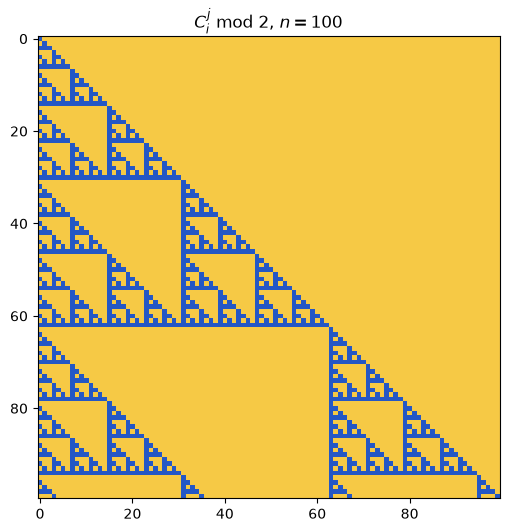

In [4]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

n=100
B=np.zeros((n,n), dtype=int)
for i in range(1, n+1):
    for j in range(1, i+1):
        B[i-1, j-1]=(j & i)==j

fig, ax=plt.subplots(figsize=(6,6))
ax.imshow(B, cmap=ListedColormap(['#F6C945','#2457C5']), interpolation='nearest')
ax.set_title(r'$C_i^j$ mod $2$, $n=100$')
plt.show()

Нижний треугольник — треугольник Серпинского, выше диагонали нули.

---
## 1.12. Матрицы Адамара

$H_n$ — матрица $n\times n$ из $\pm 1$, $H_n H_n^T=n I_n$, $H_0\equiv 1$. Индекс — порядок матрицы.

**а)** $H_1$, $H_2$, $H_4$. **б)** $H_4=H_2\otimes H_2$. **в)** $H_{2^k}=H_2\otimes H_{2^{k-1}}$. **г)** рисунок $H_{64}$.

**а)** $H_1=(1)$, дальше рекурсия Сильвестра: к матрице $H$ приписываем блоки $\begin{pmatrix}H&H\\H&-H\end{pmatrix}$.

In [47]:
H1=Matrix([[1]])
H2=Matrix([[1,1],[1,-1]])
H4=Matrix([[1,1,1,1],[1,-1,1,-1],[1,1,-1,-1],[1,-1,-1,1]])
H1, H2, H4, simplify(H2*H2.T), simplify(H4*H4.T)

⎛              ⎡1  1   1   1 ⎤          ⎡4  0  0  0⎤⎞
⎜              ⎢             ⎥          ⎢          ⎥⎟
⎜     ⎡1  1 ⎤  ⎢1  -1  1   -1⎥  ⎡2  0⎤  ⎢0  4  0  0⎥⎟
⎜[1], ⎢     ⎥, ⎢             ⎥, ⎢    ⎥, ⎢          ⎥⎟
⎜     ⎣1  -1⎦  ⎢1  1   -1  -1⎥  ⎣0  2⎦  ⎢0  0  4  0⎥⎟
⎜              ⎢             ⎥          ⎢          ⎥⎟
⎝              ⎣1  -1  -1  1 ⎦          ⎣0  0  0  4⎦⎠

**б)** Произведение Кронекера $H_2\otimes H_2$ совпадает с выписанной $H_4$.

In [48]:
kron=Matrix(np.kron(np.array(H2,dtype=int), np.array(H2,dtype=int)))
kron==H4

True

**в)** Положим $H_{2^k}=H_2\otimes H_{2^{k-1}}$ и $H_2=\begin{pmatrix}1&1\\1&-1\end{pmatrix}$. Тогда
$$
H_{2^k}H_{2^k}^T=(H_2\otimes H)(H_2^T\otimes H^T)=(H_2H_2^T)\otimes(HH^T)=(2I_2)\otimes(2^{k-1}I)=2^k I.
$$
Элементы остаются $\pm 1$. Проверка для $k=3$: $H_8=H_2\otimes H_4$ и $H_8H_8^T=8I$.

In [49]:
H8=np.kron(np.array(H2,dtype=int), np.array(H4,dtype=int))
np.array_equal(H8@H8.T, 8*np.eye(8))

True

**г)** $n=2^6=64$. Строки матрицы Сильвестра переставлены по числу перемен знака: так картинка совпадает с ответом в листке (там прямо сказано, что порядок строк другой). Оранжевый — $+1$, синий — $-1$.

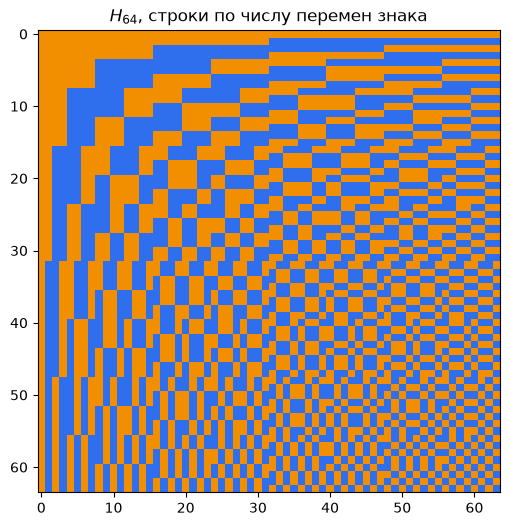

In [50]:
def sylvester(k):
    H=np.array([[1]])
    for _ in range(k):
        H=np.block([[H,H],[H,-H]])
    return H

H64=sylvester(6)
changes=np.sum(H64[:,1:]!=H64[:,:-1], axis=1)
H64=H64[np.argsort(changes)]

fig, ax=plt.subplots(figsize=(6,6))
ax.imshow(H64, cmap=ListedColormap(['#2F6FED','#F18F01']), interpolation='nearest')
ax.set_title(r'$H_{64}$, строки по числу перемен знака')
plt.show()

---
## 1.13. Собственное значение с наибольшей мнимой частью

$$
A=\begin{pmatrix}14&10&21\\12&15&26\\18&11&27\end{pmatrix}.
$$

$Z$ — собственное значение с наибольшей мнимой частью, $X=(1,U,V)$ — отвечающий ему собственный вектор. В ответе: **1)** $\operatorname{Im} Z$; **2)** $\operatorname{Re} U$.

Характеристический многочлен $t^3-56t^2+209t-208$ рациональных корней не имеет. Берём собственные пары численно и нормируем первую координату вектора на $1$.

In [51]:
A=np.array([[14,10,21],[12,15,26],[18,11,27]], dtype=float)
w,V=np.linalg.eig(A)
k=int(np.argmax(w.imag))
Z=w[k]
X=V[:,k]/V[0,k]
Z, X, round(Z.imag, 6), round(X[1].real, 6)

(np.complex128(1.968840330801648+0.34478934842718173j),
 array([ 1.        -1.73026019e-18j,  3.74781973+1.33084677e+00j,
        -2.35758843-6.17318019e-01j]),
 np.float64(0.344789),
 np.float64(3.74782))

**Ответ:** 1) $\operatorname{Im} Z\approx 0{,}344789$; 2) $\operatorname{Re} U\approx 3{,}747820$.

Вектор: $U\approx 3{,}747820+1{,}330847\,i$, $\;V\approx -2{,}357588-0{,}617318\,i$, $\;Z\approx 1{,}968840+0{,}344789\,i$.

---
## 1.14. Минимальный многочлен

$$
A=\begin{pmatrix}
-3&7&-6&-1&8&-3&-2\\
1&-5&8&-3&-5&4&-5\\
1&3&-4&6&-2&0&8\\
-1&11&-12&9&3&-3&9\\
-3&11&-12&5&8&-4&6\\
-3&2&1&-4&4&1&-7\\
1&-5&6&-2&-4&3&-2
\end{pmatrix}.
$$

Характеристический многочлен равен $\lambda^3(\lambda-1)^4$, поэтому минимальный имеет вид $\lambda^a(\lambda-1)^b$ с $a\le 3$, $b\le 4$. Ищем наименьшие показатели, при которых матрица обнуляется.

In [52]:
A=Matrix([
[-3,7,-6,-1,8,-3,-2],
[1,-5,8,-3,-5,4,-5],
[1,3,-4,6,-2,0,8],
[-1,11,-12,9,3,-3,9],
[-3,11,-12,5,8,-4,6],
[-3,2,1,-4,4,1,-7],
[1,-5,6,-2,-4,3,-2],
])
lam=symbols('lam')
print(factor(A.charpoly(lam).as_expr()))
I=eye(7)
a=1
while not (A**a*(A-I)**4).is_zero_matrix:
    a+=1
b=1
while not (A**a*(A-I)**b).is_zero_matrix:
    b+=1
a, b

lam**3*(lam - 1)**4


**Ответ:** минимальный многочлен $\lambda^3(\lambda-1)^2$.

---
## 1.15. Ортонормированный собственный базис

Самосопряжённый оператор в ортонормированном базисе:

$$
A=\begin{pmatrix}17&-8&4\\-8&17&-4\\4&-4&11\end{pmatrix}.
$$

Нужны ортонормированный базис из собственных векторов и матрица оператора в этом базисе.

Матрица симметрическая, значит собственные векторы разных значений ортогональны, а внутри кратного значения их можно ортогонализовать. В собственном базисе матрица диагональна.

In [53]:
A=Matrix([[17,-8,4],[-8,17,-4],[4,-4,11]])
cols=[]
for val, mult, vecs in sorted(A.eigenvects(), key=lambda t: t[0]):
    for v in vecs:
        v=Matrix(v)
        for u in cols:
            v-=v.dot(u)*u
        v=simplify(v/sqrt(v.dot(v)))
        for comp in v:
            if comp!=0:
                if comp<0:
                    v=-v
                break
        cols.append(v)
        print(val, v.T)
P=Matrix.hstack(*cols)
simplify(P.T*A*P)

9 Matrix([[sqrt(2)/2, sqrt(2)/2, 0]])
9 Matrix([[sqrt(2)/6, -sqrt(2)/6, -2*sqrt(2)/3]])
27 Matrix([[2/3, -2/3, 1/3]])


⎡9  0  0 ⎤
⎢        ⎥
⎢0  9  0 ⎥
⎢        ⎥
⎣0  0  27⎦

**Ответ.** Базис (значения $9,9,27$):

$$
e_1=\frac{1}{\sqrt{2}}(1,1,0),\quad
e_2=\frac{\sqrt{2}}{6}(1,-1,-4),\quad
e_3=\frac{1}{3}(2,-2,1).
$$

Матрица в этом базисе: $\operatorname{diag}(9,9,27)$.

---
## 1.16. Квадратичная форма к главным осям

$$
f=3x_1^2+8x_1x_2-3x_2^2+4x_3^2-4x_3x_4+x_4^2.
$$

Симметрическая матрица формы ($2a_{ij}$ — коэффициент при $x_ix_j$):

$$
A=\begin{pmatrix}3&4&0&0\\4&-3&0&0\\0&0&4&-2\\0&0&-2&1\end{pmatrix}.
$$

Она распадается на два блока $2\times 2$. Ортогональное преобразование $x=Py$: столбцы $P$ — ортонормированные собственные векторы.

In [54]:
s=sqrt(5)
P=Matrix([
[2/s, 0, 1/s, 0],
[1/s, 0, -2/s, 0],
[0, 2/s, 0, 1/s],
[0, -1/s, 0, 2/s],
])
A=Matrix([[3,4,0,0],[4,-3,0,0],[0,0,4,-2],[0,0,-2,1]])
simplify(P.T*P), simplify(P.T*A*P)

⎛⎡1  0  0  0⎤  ⎡5  0  0   0⎤⎞
⎜⎢          ⎥  ⎢           ⎥⎟
⎜⎢0  1  0  0⎥  ⎢0  5  0   0⎥⎟
⎜⎢          ⎥, ⎢           ⎥⎟
⎜⎢0  0  1  0⎥  ⎢0  0  -5  0⎥⎟
⎜⎢          ⎥  ⎢           ⎥⎟
⎝⎣0  0  0  1⎦  ⎣0  0  0   0⎦⎠

**Ответ.** $x=Py$ с матрицей

$$
P=\frac{1}{\sqrt{5}}\begin{pmatrix}2&0&1&0\\1&0&-2&0\\0&2&0&1\\0&-1&0&2\end{pmatrix},
$$

и в новых координатах $f=5y_1^2+5y_2^2-5y_3^2$.

---
## 1.17. Кривые второго порядка

**а)** $5x^2+4xy+8y^2-32x-56y+80=0$.

**б)** $5x^2+12xy-22x-12y-19=0$.

Квадратичная часть приводится поворотом (собственные векторы), линейная — сдвигом.

**а)** Матрица квадратичной части $\begin{pmatrix}5&2\\2&8\end{pmatrix}$, собственные значения $4$ и $9$, оба положительны, кривая невырождена — эллипс.

In [55]:
s=sqrt(5)
P=Matrix([[-2/s,-1/s],[1/s,-2/s]])
A=Matrix([[5,2],[2,8]])
D=simplify(P.T*A*P)
lin=simplify(Matrix([[-32,-56]])*P)
l1,l2=D[0,0],D[1,1]
p,q=lin
rhs=simplify(p**2/(4*l1)+q**2/(4*l2)-80)
shift=Matrix([simplify(p/(2*l1)), simplify(q/(2*l2))])
origin=simplify(P*(-shift))
D, rhs, simplify(rhs/l1), simplify(rhs/l2), origin.T

⎛⎡4  0⎤                  ⎞
⎜⎢    ⎥, 36, 9, 4, [2  3]⎟
⎝⎣0  9⎦                  ⎠

**б)** Матрица $\begin{pmatrix}5&6\\6&0\end{pmatrix}$, собственные значения $9$ и $-4$, разных знаков — гипербола.

In [56]:
s=sqrt(13)
P=Matrix([[3/s,-2/s],[2/s,3/s]])
A=Matrix([[5,6],[6,0]])
D=simplify(P.T*A*P)
lin=simplify(Matrix([[-22,-12]])*P)
l1,l2=D[0,0],D[1,1]
p,q=lin
rhs=simplify(p**2/(4*l1)+q**2/(4*l2)-(-19))
shift=Matrix([simplify(p/(2*l1)), simplify(q/(2*l2))])
origin=simplify(P*(-shift))
D, rhs, simplify(rhs/l1), simplify(rhs/l2), origin.T

⎛⎡9  0 ⎤                   ⎞
⎜⎢     ⎥, 36, 4, -9, [1  1]⎟
⎝⎣0  -4⎦                   ⎠

**Ответ.**

а) Эллипс $\dfrac{X^2}{9}+\dfrac{Y^2}{4}=1$. Канонические координаты:

$$
\begin{pmatrix}x\\y\end{pmatrix}
=\begin{pmatrix}2\\3\end{pmatrix}
+\frac{1}{\sqrt{5}}\begin{pmatrix}-2&-1\\1&-2\end{pmatrix}
\begin{pmatrix}X\\Y\end{pmatrix}.
$$

б) Гипербола $\dfrac{X^2}{4}-\dfrac{Y^2}{9}=1$. Канонические координаты:

$$
\begin{pmatrix}x\\y\end{pmatrix}
=\begin{pmatrix}1\\1\end{pmatrix}
+\frac{1}{\sqrt{13}}\begin{pmatrix}3&-2\\2&3\end{pmatrix}
\begin{pmatrix}X\\Y\end{pmatrix}.
$$

---
## 1.18. Положительная определённость

$$
Q=x_1^2+4x_2^2+x_3^2+2\lambda x_1x_2+10x_1x_3+6x_2x_3.
$$

Матрица формы:

$$
A=\begin{pmatrix}1&\lambda&5\\\lambda&4&3\\5&3&1\end{pmatrix}.
$$

Главный минор по $x_1,x_3$ не зависит от $\lambda$: $\begin{vmatrix}1&5\\5&1\end{vmatrix}=-24<0$. У положительно определённой формы все главные миноры положительны, поэтому таких $\lambda$ нет.

In [57]:
lam=symbols('lam')
A=Matrix([[1,lam,5],[lam,4,3],[5,3,1]])
minor13=Matrix([[1,5],[5,1]]).det()
minor13, factor(A.det())

**Ответ:** ни при каком $\lambda$. Форма не является положительно определённой.

---
## 1.19. Отрицательная определённость

$$
Q=\lambda x_1^2-2x_2^2-3x_3^2+2x_1x_2-2x_1x_3+2x_2x_3.
$$

$$
A=\begin{pmatrix}\lambda&1&-1\\1&-2&1\\-1&1&-3\end{pmatrix}.
$$

Форма отрицательно определена, когда угловые миноры чередуют знаки: $\Delta_1<0$, $\Delta_2>0$, $\Delta_3<0$.

In [58]:
lam=symbols('lam', real=True)
A=Matrix([[lam,1,-1],[1,-2,1],[-1,1,-3]])
d1=A[:1,:1].det()
d2=factor(A[:2,:2].det())
d3=factor(A.det())
d1, d2, d3

$\Delta_1=\lambda<0$, $\;\Delta_2=-2\lambda-1>0$ даёт $\lambda<-1/2$, $\;\Delta_3=5\lambda+3<0$ даёт $\lambda<-3/5$. Самое сильное условие — последнее.

**Ответ:** $\lambda<-3/5$.

---
## 1.20. Эквивалентность квадратичных форм

$$
\begin{aligned}
Q_1&=2x_1^2+9x_2^2+3x_3^2+8x_1x_2-4x_1x_3-10x_2x_3,\\
Q_2&=2x_1^2+3x_2^2+6x_3^2-4x_1x_2-4x_1x_3+8x_2x_3.
\end{aligned}
$$

Над $\mathbb{R}$ две квадратичные формы эквивалентны, когда совпадают ранг и сигнатура: число положительных, отрицательных и нулевых собственных значений.

In [59]:
lam=symbols('lam')
Q1=Matrix([[2,4,-2],[4,9,-5],[-2,-5,3]])
Q2=Matrix([[2,-2,-2],[-2,3,4],[-2,4,6]])
factor(Q1.charpoly(lam).as_expr()), factor(Q2.charpoly(lam).as_expr())

У $Q_1$ многочлен $\lambda(\lambda^2-14\lambda+6)$. Корни $0$ и $7\pm\sqrt{43}$: оба ненулевых корня положительны, потому что $\sqrt{43}<7$.

У $Q_2$ многочлен $\lambda(\lambda^2-11\lambda+12)$. Корни $0$ и $(11\pm\sqrt{73})/2$, тоже оба положительны.

Ранг $2$, сигнатура $(2,0)$ у обеих форм.

**Ответ:** да, эквивалентны.